In [ ]:
import numpy as np
import pandas as pd

In [ ]:
pip install ucimlrepo

In [ ]:
# Get Dataset from -> URL : https://archive.ics.uci.edu/dataset/9/auto+mpg

from ucimlrepo import fetch_ucirepo

# fetch dataset
auto_mpg = fetch_ucirepo(id=9)

# data (as pandas dataframes)
X = auto_mpg.data.features
y = auto_mpg.data.targets.squeeze()

# metadata
print(auto_mpg.metadata)

# variable information
print(auto_mpg.variables)

{'uci_id': 9, 'name': 'Auto MPG', 'repository_url': 'https://archive.ics.uci.edu/dataset/9/auto+mpg', 'data_url': 'https://archive.ics.uci.edu/static/public/9/data.csv', 'abstract': 'Revised from CMU StatLib library, data concerns city-cycle fuel consumption', 'area': 'Other', 'tasks': ['Regression'], 'characteristics': ['Multivariate'], 'num_instances': 398, 'num_features': 7, 'feature_types': ['Real', 'Categorical', 'Integer'], 'demographics': [], 'target_col': ['mpg'], 'index_col': ['car_name'], 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1993, 'last_updated': 'Thu Aug 10 2023', 'dataset_doi': '10.24432/C5859H', 'creators': ['R. Quinlan'], 'intro_paper': None, 'additional_info': {'summary': 'This dataset is a slightly modified version of the dataset provided in the StatLib library.  In line with the use by Ross Quinlan (1993) in predicting the attribute "mpg", 8 of the original instances were removed because they had unknown values for th

In [ ]:
X

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin
0,307.0,8,130.0,3504,12.0,70,1
1,350.0,8,165.0,3693,11.5,70,1
2,318.0,8,150.0,3436,11.0,70,1
3,304.0,8,150.0,3433,12.0,70,1
4,302.0,8,140.0,3449,10.5,70,1
...,...,...,...,...,...,...,...
393,140.0,4,86.0,2790,15.6,82,1
394,97.0,4,52.0,2130,24.6,82,2
395,135.0,4,84.0,2295,11.6,82,1
396,120.0,4,79.0,2625,18.6,82,1


In [ ]:
y

,mpg
0,18.0
1,15.0
2,18.0
3,16.0
4,17.0
...,...
393,27.0
394,44.0
395,32.0
396,28.0


In [ ]:
X.isnull().sum()

,0
displacement,0
cylinders,0
horsepower,6
weight,0
acceleration,0
model_year,0
origin,0


In [ ]:
X['horsepower'].dtype

dtype('float64')

In [ ]:
X['horsepower'].fillna(X['horsepower'].mean(),inplace=True)

/tmp/ipykernel_701/2003055745.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  X['horsepower'].fillna(X['horsepower'].mean(),inplace=True)
/tmp/ipykernel_701/2003055745.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['horsepower'].fillna(X['horsepower'].mean(),inplace=True)


In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_train_scaled = pd.DataFrame(X_train_scaled,columns=X_train.columns,index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled,columns=X_test.columns,index=X_test.index)

In [ ]:
def gradient_descent(X,y,lr,max_iter):
  n = X.shape[0] # Number of data
  p = X.shape[1] # Number of features

  # Initial Weights
  w = np.zeros(p)
  b=0
  loss=[]

  for i in range(max_iter):
    y_pred = X.dot(w) + b
    db = (-2/n) * np.sum(y-y_pred)
    dw = (-2/n) * np.dot(X.T,(y-y_pred))
    b = b - lr * db
    w = w - lr * dw
    loss.append(np.mean((y-y_pred)**2))

  return b,w,loss

In [ ]:
b,w,loss = gradient_descent(X_train_scaled,y_train,0.01,1000)

In [ ]:
def predict(X,b,w):
  return X.dot(w) + b

In [ ]:
y_pred_gd=predict(X_test_scaled,b,w)

In [ ]:
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(y_test,y_pred_gd)
print(mse)

8.509477895122497


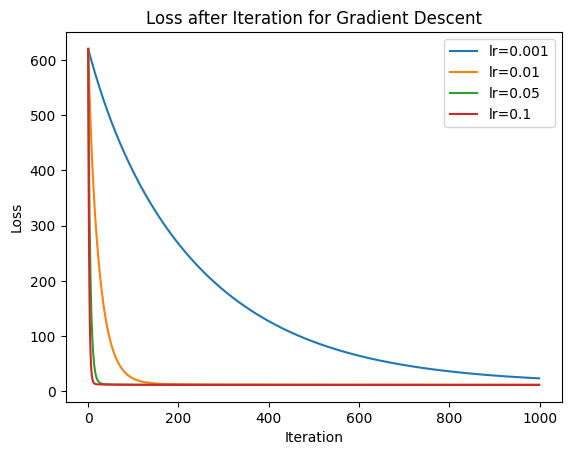

In [31]:
# plot error vs iteration
import matplotlib.pyplot as plt
l=[0.001,0.01,0.05,0.1]
plt.figure()
for lr in l:
  b,w,loss = gradient_descent(X_train_scaled,y_train,lr,1000)
  plt.plot(loss,label=f'lr={lr}')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.legend()
plt.title('Loss after Iteration for Gradient Descent')
plt.show()

In [ ]:
# Just checking the difference of accuracy between this model and sklearn model
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X_train_scaled,y_train)

LinearRegression()

In [ ]:
y_pred = lr.predict(X_test_scaled)
mse = mean_squared_error(y_test,y_pred)
print(mse)

8.195452104073777


In [ ]:
def sign(w):
  return np.where(w==0, np.random.uniform(-1,1,size=w.shape), np.sign(w))

In [ ]:
def subgradient(X,y,lr,max_iter,alpha):
  n = X.shape[0] # Number of data
  p = X.shape[1] # Number of features

  # Initial Weights
  w = np.zeros(p)
  b=0
  loss=[]

  for i in range(max_iter):
    y_pred = X.dot(w) + b
    db = (-2/n) * np.sum(y-y_pred)
    dw = (-2/n) * np.dot(X.T,(y-y_pred)) + alpha*sign(w)
    b = b - lr * db
    w = w - lr * dw
    loss.append(np.mean((y-y_pred)**2) + alpha*np.sum(np.abs(w)))

  return b,w,loss

In [ ]:
b,w,loss = subgradient(X_train_scaled,y_train,0.01,1000,0.01)

In [ ]:
y_pred_sg=predict(X_test_scaled,b,w)

In [ ]:
mse = mean_squared_error(y_test,y_pred_sg)
print(mse)

8.502343845049731


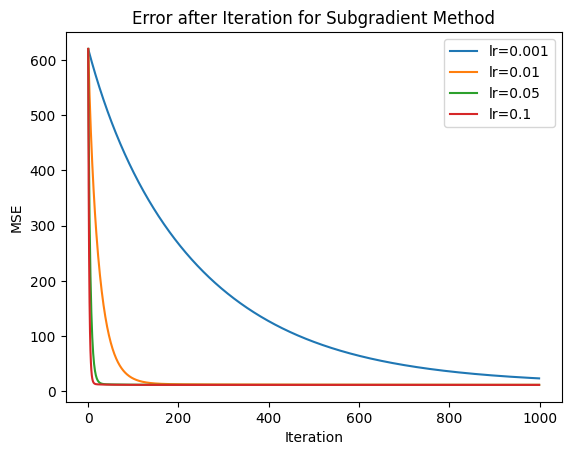

In [ ]:
# plot error vs iteration
l=[0.001,0.01,0.05,0.1]
plt.figure()
for lr in l:
  b,w,loss = subgradient(X_train_scaled,y_train,lr,1000,0.01)
  plt.plot(loss,label=f'lr={lr}')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.legend()
plt.title('Loss after Iteration for Subgradient Method')
plt.show()